# Healthcare Utilization & Cost Analytics
## 01. Data Profiling

## 1. Import Libraries

In [107]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

## 2. Locate CSV Files

In [108]:
data_dir = Path("../data/raw")

for file in sorted(data_dir.glob("*.csv")):
    print(file.name)

allergies.csv
careplans.csv
conditions.csv
devices.csv
encounters.csv
imaging_studies.csv
immunizations.csv
medications.csv
observations.csv
organizations.csv
patients.csv
payer_transitions.csv
payers.csv
procedures.csv
providers.csv
supplies.csv


## 3. Load Data

In [109]:
dataframes = {}

for file in sorted(data_dir.glob("*.csv")):
    df = pd.read_csv(file, low_memory=False)
    dataframes[file.stem] = df

    print(
        f"{file.name}: "
        f"{df.shape[0]:,} rows, "
        f"{df.shape[1]} columns"
    )

print(f"\nLoaded {len(dataframes)} CSV files.")

allergies.csv: 597 rows, 6 columns
careplans.csv: 3,483 rows, 9 columns
conditions.csv: 8,376 rows, 6 columns
devices.csv: 78 rows, 7 columns
encounters.csv: 53,346 rows, 15 columns
imaging_studies.csv: 855 rows, 10 columns
immunizations.csv: 15,478 rows, 6 columns
medications.csv: 42,989 rows, 13 columns
observations.csv: 299,697 rows, 8 columns
organizations.csv: 1,119 rows, 11 columns
patients.csv: 1,171 rows, 25 columns
payer_transitions.csv: 3,801 rows, 5 columns
payers.csv: 10 rows, 21 columns
procedures.csv: 34,981 rows, 8 columns
providers.csv: 5,855 rows, 12 columns
supplies.csv: 0 rows, 6 columns

Loaded 16 CSV files.


## 4. Patients: Overview and Data Quality

In [110]:
patients = dataframes["patients"]

patients["ZIP"] = patients["ZIP"].astype("Int64").astype("string").str.zfill(5)

sensitive_cols = ["SSN", "DRIVERS", "PASSPORT", "PREFIX", "FIRST", "LAST", "SUFFIX", "MAIDEN", "ADDRESS"]
display(patients.drop(columns=sensitive_cols).head())

,Id,BIRTHDATE,DEATHDATE,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,CITY,STATE,COUNTY,ZIP,LAT,LON,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE
0,1d604da9-9a81-4ba9-80c2-de3375d59b40,1989-05-25,NaN,M,white,hispanic,M,Marigot Saint Andrew Parish DM,Chicopee,Massachusetts,Hampden County,01013,42.228354,-72.562951,271227.08,1334.88
1,034e9e3b-2def-4559-bb2a-7850888ae060,1983-11-14,NaN,M,white,nonhispanic,M,Danvers Massachusetts US,Somerville,Massachusetts,Middlesex County,02143,42.360697,-71.126531,793946.01,3204.49
2,10339b10-3cd1-4ac3-ac13-ec26728cb592,1992-06-02,NaN,M,white,nonhispanic,M,Springfield Massachusetts US,Chicopee,Massachusetts,Hampden County,01020,42.181642,-72.608842,574111.90,2606.40
3,8d4c4326-e9de-4f45-9a4c-f8c36bff89ae,1978-05-27,NaN,M,white,nonhispanic,F,Yarmouth Massachusetts US,Lowell,Massachusetts,Middlesex County,01851,42.636143,-71.343255,935630.30,8756.19
4,f5dcd418-09fe-4a2f-baa0-3da800bd8c3a,1996-10-18,NaN,NaN,white,nonhispanic,M,Patras Achaea GR,Boston,Massachusetts,Suffolk County,02135,42.352434,-71.028610,598763.07,3772.20


### 4.1 Table Size and Unique IDs

In [111]:
print("Rows:", patients.shape[0])
print("Columns:", patients.shape[1])
print("Unique patient IDs:", patients["Id"].nunique())
print("\nColumn names:")
print(list(patients.columns))

Rows: 1171
Columns: 25
Unique patient IDs: 1171

Column names:
['Id', 'BIRTHDATE', 'DEATHDATE', 'SSN', 'DRIVERS', 'PASSPORT', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON', 'HEALTHCARE_EXPENSES', 'HEALTHCARE_COVERAGE']


### 4.2 Column Types

In [112]:
patients.info()

<class 'pandas.DataFrame'>
RangeIndex: 1171 entries, 0 to 1170
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   1171 non-null   str    
 1   BIRTHDATE            1171 non-null   str    
 2   DEATHDATE            171 non-null    str    
 3   SSN                  1171 non-null   str    
 4   DRIVERS              958 non-null    str    
 5   PASSPORT             898 non-null    str    
 6   PREFIX               927 non-null    str    
 7   FIRST                1171 non-null   str    
 8   LAST                 1171 non-null   str    
 9   SUFFIX               12 non-null     str    
 10  MAIDEN               331 non-null    str    
 11  MARITAL              791 non-null    str    
 12  RACE                 1171 non-null   str    
 13  ETHNICITY            1171 non-null   str    
 14  GENDER               1171 non-null   str    
 15  BIRTHPLACE           1171 non-null   str    
 16 

### 4.3 Missing Values

In [113]:
missing = patients.isna().sum().to_frame("missing")
missing["missing_pct"] = (missing["missing"] / len(patients) * 100).round(1)
missing.sort_values("missing", ascending=False)

,missing,missing_pct
SUFFIX,1159,99.0
DEATHDATE,1000,85.4
MAIDEN,840,71.7
ZIP,543,46.4
MARITAL,380,32.5
PASSPORT,273,23.3
PREFIX,244,20.8
DRIVERS,213,18.2
Id,0,0.0
LAST,0,0.0


### 4.4 Duplicates

In [114]:
print("Duplicated rows:", patients.duplicated().sum())
print("Duplicated IDs:", patients["Id"].duplicated().sum())

Duplicated rows: 0
Duplicated IDs: 0


### 4.5 Date Conversion and Age

In [115]:
patients["BIRTHDATE"] = pd.to_datetime(patients["BIRTHDATE"])
patients["DEATHDATE"] = pd.to_datetime(patients["DEATHDATE"])

# Reference date = end of the data (last encounter), not today's date
reference_date = pd.to_datetime(dataframes["encounters"]["START"], utc=True).max().tz_localize(None)
print("Reference date:", reference_date.date())

# Living patients: age at reference date. Deceased patients: age at death.
end_date = patients["DEATHDATE"].fillna(reference_date)
patients["AGE"] = ((end_date - patients["BIRTHDATE"]).dt.days / 365.25).round(0)
patients["IS_DECEASED"] = patients["DEATHDATE"].notna()

print("Deceased patients:", patients["IS_DECEASED"].sum())
print("Patients older than 100:", (patients["AGE"] > 100).sum())
patients["AGE"].describe()

Reference date: 2020-04-28
Deceased patients: 171
Patients older than 100: 11


count    1171.000000
mean       41.663535
std        24.307774
min         0.000000
25%        21.000000
50%        42.000000
75%        61.000000
max       110.000000
Name: AGE, dtype: float64

### 4.6 Demographics

In [116]:
print(patients["GENDER"].value_counts())
print()
print(patients["RACE"].value_counts())
print()
print(patients["MARITAL"].value_counts(dropna=False))

GENDER
F    609
M    562
Name: count, dtype: int64

RACE
white     965
black     101
asian      90
native     13
other       2
Name: count, dtype: int64

MARITAL
M      638
NaN    380
S      153
Name: count, dtype: int64


In [117]:
print(patients.groupby(patients["MARITAL"].isna())["AGE"].describe().round(1))

         count  mean   std   min   25%   50%   75%    max
MARITAL                                                  
False    791.0  54.9  17.5  27.0  41.0  54.0  66.5  110.0
True     380.0  14.2   7.9   0.0   7.8  15.0  21.0   27.0


### 4.7 Age Distribution

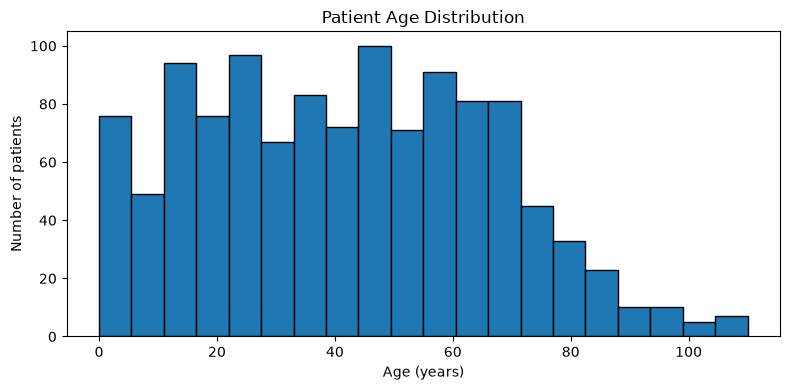

In [118]:
plt.figure(figsize=(8, 4))
plt.hist(patients["AGE"].dropna(), bins=20, edgecolor="black")
plt.title("Patient Age Distribution")
plt.xlabel("Age (years)")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.show()

### 4.8 Healthcare Expenses and Coverage

In [119]:
patients[["HEALTHCARE_EXPENSES", "HEALTHCARE_COVERAGE"]].describe().round(0)

,HEALTHCARE_EXPENSES,HEALTHCARE_COVERAGE
count,1171.0,1171.0
mean,764941.0,12933.0
std,546475.0,43882.0
min,1822.0,0.0
25%,233552.0,3101.0
50%,718679.0,5742.0
75%,1260844.0,10569.0
max,2145924.0,927874.0


### 4.9 Key Findings: Patients

- **Size and integrity:** 1,171 patients, 25 columns. All patient IDs are unique, no duplicated rows.
- **Missing values:** Gaps are mostly expected. `SUFFIX` (99%), `MAIDEN` (72%) and `PREFIX` (21%) are optional by nature. `DEATHDATE` is empty for living patients (85.4%), so 171 patients (14.6%) are deceased. `MARITAL` is missing for 32.5% of patients, all of whom are aged 27 or younger, so this gap is age-related and expected. `ZIP` is missing for 46% of patients, which is a real data quality gap, so geographic analysis will use `CITY` and `COUNTY` instead.
- **Demographics:** 52.0% female / 48.0% male. Race: 82.4% white, 8.6% black, 7.7% asian, 1.1% native, 0.2% other. Marital status contains only married (54.5%) and single (13.1%).
- **Age:** Patients range from 0 to 110 years (median 42). Counts are spread fairly evenly up to ~70, then fall. 11 patients are over 100 years old (10 living, 1 deceased), which is unusual and likely a feature of the synthetic data. Age is calculated at the date of the last encounter (2020-04-28) for living patients and at death for deceased ones.
- **Costs (patient level):** Lifetime healthcare expenses average ~$765K (median ~$719K), while payer coverage averages ~$12.9K (median ~$5.7K). Coverage is strongly right-skewed (max ~$928K). Both are lifetime totals in synthetic data, so they should not be generalized to real healthcare systems.
- **Privacy:** Personal identifiers are hidden in all previews. The dataset is fully synthetic.

## 5. Encounters: Overview and Data Quality

In [120]:
encounters = dataframes["encounters"]

print("Rows:", encounters.shape[0])
print("Columns:", encounters.shape[1])
print("Unique encounter IDs:", encounters["Id"].nunique())
print("Unique patients with encounters:", encounters["PATIENT"].nunique())
print("\nColumn names:")
print(list(encounters.columns))

Rows: 53346
Columns: 15
Unique encounter IDs: 53346
Unique patients with encounters: 1171

Column names:
['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PROVIDER', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']


### 5.1 Column Types and Missing Values

In [121]:
encounters.info()

missing = encounters.isna().sum().to_frame("missing")
missing["missing_pct"] = (missing["missing"] / len(encounters) * 100).round(1)
missing.sort_values("missing", ascending=False)

<class 'pandas.DataFrame'>
RangeIndex: 53346 entries, 0 to 53345
Data columns (total 15 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Id                   53346 non-null  str    
 1   START                53346 non-null  str    
 2   STOP                 53346 non-null  str    
 3   PATIENT              53346 non-null  str    
 4   ORGANIZATION         53346 non-null  str    
 5   PROVIDER             53346 non-null  str    
 6   PAYER                53346 non-null  str    
 7   ENCOUNTERCLASS       53346 non-null  str    
 8   CODE                 53346 non-null  int64  
 9   DESCRIPTION          53346 non-null  str    
 10  BASE_ENCOUNTER_COST  53346 non-null  float64
 11  TOTAL_CLAIM_COST     53346 non-null  float64
 12  PAYER_COVERAGE       53346 non-null  float64
 13  REASONCODE           13777 non-null  float64
 14  REASONDESCRIPTION    13777 non-null  str    
dtypes: float64(4), int64(1), str(10)
memory usage: 

,missing,missing_pct
REASONCODE,39569,74.2
REASONDESCRIPTION,39569,74.2
Id,0,0.0
PATIENT,0,0.0
ORGANIZATION,0,0.0
START,0,0.0
STOP,0,0.0
PAYER,0,0.0
PROVIDER,0,0.0
ENCOUNTERCLASS,0,0.0


### 5.2 Duplicates

In [122]:
print("Duplicated rows:", encounters.duplicated().sum())
print("Duplicated encounter IDs:", encounters["Id"].duplicated().sum())

Duplicated rows: 0
Duplicated encounter IDs: 0


### 5.3 Date Conversion

In [123]:
encounters["START"] = pd.to_datetime(encounters["START"], utc=True).dt.tz_localize(None)
encounters["STOP"] = pd.to_datetime(encounters["STOP"], utc=True).dt.tz_localize(None)

print("First encounter:", encounters["START"].min())
print("Last encounter:", encounters["START"].max())

# Data quality check: a visit should not end before it starts
print("Encounters ending before start:", (encounters["STOP"] < encounters["START"]).sum())

First encounter: 1912-07-21 19:05:21
Last encounter: 2020-04-28 18:58:37
Encounters ending before start: 0


### 5.4 Encounter Types

,encounters,pct
ENCOUNTERCLASS,,
wellness,19106,35.8
ambulatory,18936,35.5
outpatient,9003,16.9
urgentcare,2373,4.4
emergency,2090,3.9
inpatient,1838,3.4


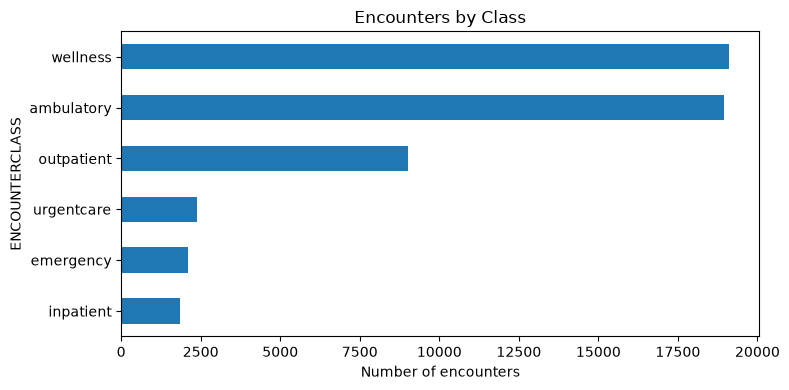

In [124]:
encounter_types = encounters["ENCOUNTERCLASS"].value_counts().to_frame("encounters")
encounter_types["pct"] = (encounter_types["encounters"] / len(encounters) * 100).round(1)
display(encounter_types)

encounter_types["encounters"].plot(kind="barh", figsize=(8, 4), title="Encounters by Class")
plt.xlabel("Number of encounters")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 5.5 Encounters Over Time

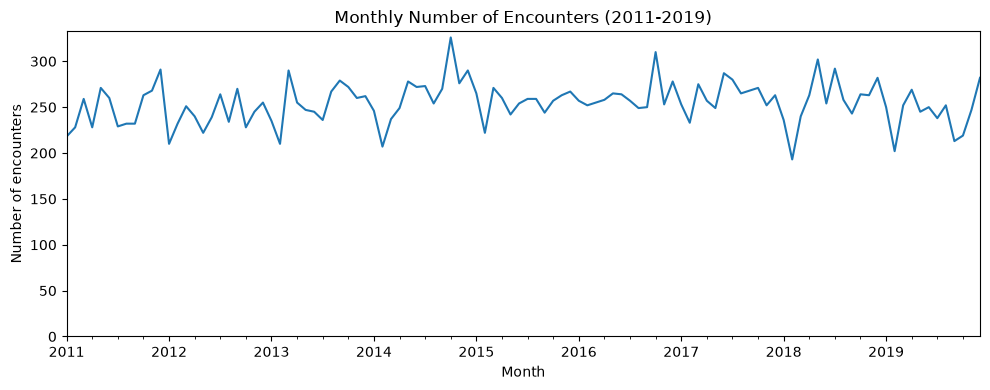

In [125]:
# Full-coverage years only: earlier history is sparse, 2020 is incomplete
full_years = encounters[(encounters["START"].dt.year >= 2011) & (encounters["START"].dt.year <= 2019)]
monthly = full_years.groupby(full_years["START"].dt.to_period("M")).size()

monthly.plot(figsize=(10, 4), title="Monthly Number of Encounters (2011-2019)")
plt.xlabel("Month")
plt.ylabel("Number of encounters")
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

### 5.6 Costs

In [126]:
cost_cols = ["BASE_ENCOUNTER_COST", "TOTAL_CLAIM_COST", "PAYER_COVERAGE"]
existing = [c for c in cost_cols if c in encounters.columns]
print("Found:", existing)
print("Missing:", [c for c in cost_cols if c not in encounters.columns])

encounters[existing].describe().round(2)

Found: ['BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE']
Missing: []


,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE
count,53346.00,53346.00,53346.00
mean,128.75,128.75,62.00
std,4.58,4.58,43.61
min,77.49,77.49,0.00
25%,129.16,129.16,17.49
50%,129.16,129.16,69.16
75%,129.16,129.16,89.16
max,129.16,129.16,129.16


### 5.7 Payer Coverage by Encounter Class

In [127]:
by_class = encounters.groupby("ENCOUNTERCLASS").agg(
    encounters=("Id", "size"),
    total_cost=("TOTAL_CLAIM_COST", "sum"),
    payer_coverage=("PAYER_COVERAGE", "sum"),
)
by_class["coverage_pct"] = (by_class["payer_coverage"] / by_class["total_cost"] * 100).round(1)
by_class.sort_values("coverage_pct", ascending=False).round(0)

,encounters,total_cost,payer_coverage,coverage_pct
ENCOUNTERCLASS,,,,
wellness,19106,2467731.0,1771020.0,72.0
emergency,2090,269944.0,123087.0,46.0
ambulatory,18936,2445774.0,1066074.0,44.0
inpatient,1838,215540.0,81348.0,38.0
outpatient,9003,1162827.0,265863.0,23.0
urgentcare,2373,306497.0,0.0,0.0


### 5.8 Key Findings: Encounters

- **Size and integrity:** 53,346 encounters from all 1,171 patients (median 27 per patient). No duplicates, no encounters ending before they start. Only `REASONCODE` / `REASONDESCRIPTION` have gaps (74%), which is expected because not every visit has a recorded reason.
- **Encounter types:** Wellness (35.8%) and ambulatory (35.5%) visits dominate, followed by outpatient (16.9%). Urgent care (4.4%), emergency (3.9%) and inpatient (3.4%) are rare.
- **Time coverage:** Encounters span 1912-2020, but volume jumps to ~3,000 per year from 2011, so trends are analysed for 2011-2019 only. Within those years volume is stable at roughly 250 encounters per month with no visible trend. 2020 is incomplete (data ends 2020-04-28).
- **Costs:** Encounter cost is almost constant (~$129), so this table says little about cost differences between visit types. Payers covered 48.2% of total claim costs overall, from 0% for urgent care to 71.8% for wellness visits.
- **Data quality check:** 9 encounters start after the patient's date of death; to be investigated.

## 6. Profiling of All Tables

In [ ]:
profile_rows = []
for name, df in dataframes.items():
    profile_rows.append({
        "table": name,
        "rows": len(df),
        "columns": df.shape[1],
        "duplicated_rows": int(df.duplicated().sum()),
        "columns_with_missing": int((df.isna().sum() > 0).sum()),
        "max_missing_pct": round(df.isna().mean().max() * 100, 1) if len(df) > 0 else None,
    })

profile = pd.DataFrame(profile_rows).sort_values("rows", ascending=False)
profile

## 7. Referential Integrity

In [ ]:
# (child table, foreign key column, parent table, parent key column)
checks = [
    ("encounters", "PATIENT", "patients", "Id"),
    ("encounters", "ORGANIZATION", "organizations", "Id"),
    ("encounters", "PROVIDER", "providers", "Id"),
    ("encounters", "PAYER", "payers", "Id"),
    ("conditions", "ENCOUNTER", "encounters", "Id"),
    ("procedures", "ENCOUNTER", "encounters", "Id"),
    ("observations", "ENCOUNTER", "encounters", "Id"),
    ("medications", "ENCOUNTER", "encounters", "Id"),
    ("immunizations", "ENCOUNTER", "encounters", "Id"),
    ("allergies", "ENCOUNTER", "encounters", "Id"),
    ("careplans", "ENCOUNTER", "encounters", "Id"),
    ("imaging_studies", "ENCOUNTER", "encounters", "Id"),
    ("devices", "ENCOUNTER", "encounters", "Id"),
]

result_rows = []
for child, fk, parent, pk in checks:
    orphans = (~dataframes[child][fk].isin(dataframes[parent][pk])).sum()
    result_rows.append({
        "child_table": child,
        "foreign_key": fk,
        "parent_table": parent,
        "rows": len(dataframes[child]),
        "orphan_rows": int(orphans),
    })

pd.DataFrame(result_rows)

### 7.1 Key Findings: All Tables

- **Tables:** 16 tables loaded. `supplies.csv` is empty (0 rows). The largest tables are `observations` (299,697 rows), `encounters` (53,346) and `medications` (42,989).
- **Duplicates:** No duplicated rows in any table except `observations` (442 duplicated rows).
- **Referential integrity:** All encounters link to an existing patient, organization, provider and payer, and every filled-in `ENCOUNTER` value in the clinical tables points to an existing encounter.
- **Observations:** 30,363 observations (10.1%) have an empty `ENCOUNTER` field, so they cannot be linked to any visit. Notebook 03 shows that all of them are quality-of-life indicators (`QALY`, `DALY`, `QOLS`), so this is expected.
- **Missing values:** Large gaps appear mostly in end-date columns (for example `STOP` in `allergies` and `devices`) and optional reason fields, which is expected for ongoing or unrecorded events.